Number of simulated events = 1000000

RAW GEANT4 DETECTOR SPECTRUM
Total events             = 1000000
Events with Edep > 0     = 198512
Events with Edep = 0     = 801488
Maximum deposited energy = 662.0000000000007 keV

RAW 662-keV PHOTOPEAK
Number of events = 19871
Mean             = 661.9841267035139 keV
Std Dev          = 0.40841523279503206 keV

THEORETICAL FANO LIMIT AT 662 keV
Fano factor F       = 0.1300
Pair energy epsilon = 2.9600 eV
Sigma               = 0.5047 keV
FWHM                = 1.1885 keV
Resolution          = 0.1795 %


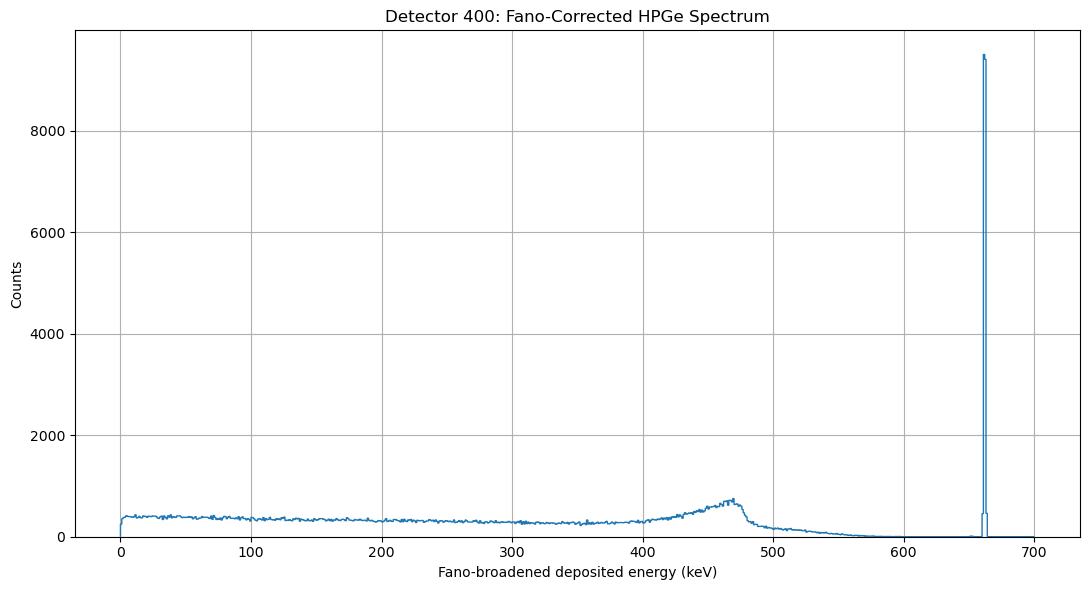


FANO-BROADENED PHOTOPEAK
Number of events = 19841
Mean = 661.9969672601239 keV
Std = 0.5011330277265177 keV

GAUSSIAN FIT RESULTS
Peak energy = 661.9950 keV
Sigma       = 0.4955 keV
FWHM        = 1.1667 keV
Resolution  = 0.1762 %
Left FWHM   = 661.4116 keV
Right FWHM  = 662.5784 keV


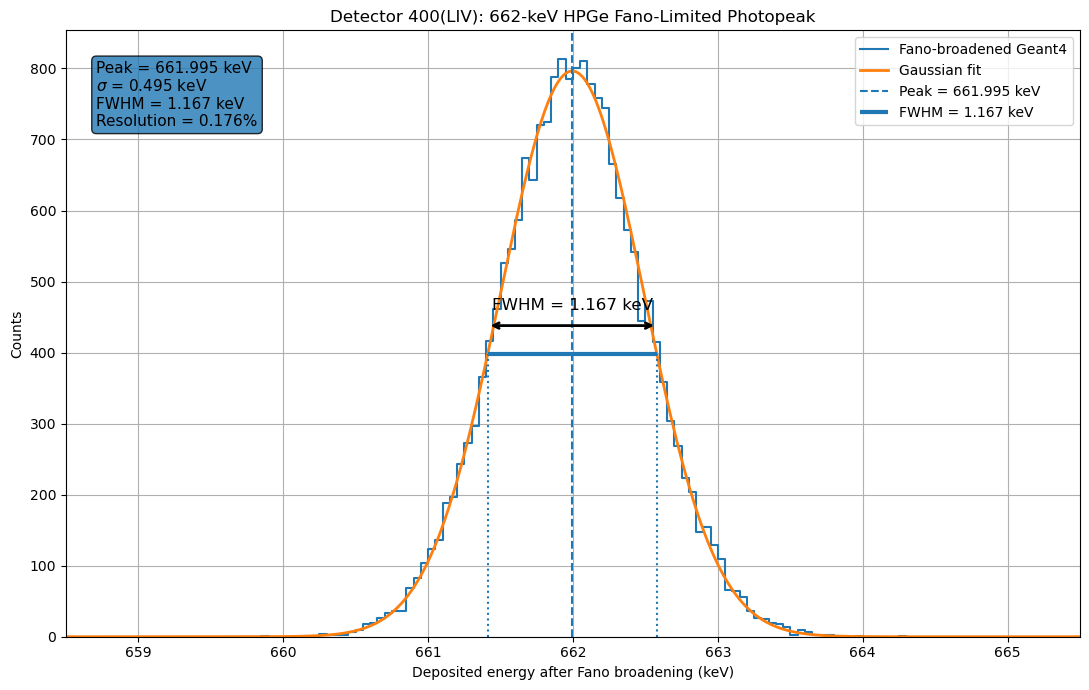

In [8]:
import ROOT
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================================================
# 1. SETTINGS
# ============================================================

file_path = "/root/geant4/detector/Det_MR/AK01_400_LIV.root"
tree_name = "t"

# Actual HPGe detector volume
detector_volume = 400

# ------------------------------------------------------------
# Germanium detector parameters
# ------------------------------------------------------------

# Mean energy required to produce one electron-hole pair
epsilon_eV = 2.96       # eV

# Fano factor for germanium
Fano = 0.13

GAUSS_TO_FWHM = 2.35482

# Random seed for reproducibility
rng = np.random.default_rng(12345)


# ============================================================
# 2. OPEN ROOT FILE
# ============================================================

f = ROOT.TFile.Open(file_path)

if not f or f.IsZombie():
    raise OSError("Cannot open ROOT file.")

tree = f.Get(tree_name)

if not tree:
    raise KeyError(f"TTree '{tree_name}' not found.")

print("Number of simulated events =", tree.GetEntries())


# ============================================================
# 3. TOTAL ENERGY DEPOSITION PER EVENT IN DETECTOR 400
# ============================================================

event_edep = []

for event in tree:

    E_sum = 0.0

    n = min(
        len(event.vlm),
        len(event.de)
    )

    for i in range(n):

        if int(event.vlm[i]) != detector_volume:
            continue

        de = float(event.de[i])

        if de > 0:
            E_sum += de

    event_edep.append(E_sum)


f.Close()

event_edep = np.asarray(event_edep, dtype=float)


# ============================================================
# 4. RAW GEANT4 INFORMATION
# ============================================================

hit_energy = event_edep[event_edep > 0]

print("\n==========================================")
print("RAW GEANT4 DETECTOR SPECTRUM")
print("==========================================")

print("Total events             =", len(event_edep))
print("Events with Edep > 0     =", len(hit_energy))
print("Events with Edep = 0     =", np.sum(event_edep == 0))
print("Maximum deposited energy =", np.max(hit_energy), "keV")


# ============================================================
# 5. RAW 662-keV PHOTOPEAK
# ============================================================

raw_photopeak = hit_energy[
    (hit_energy >= 640.0) &
    (hit_energy <= 670.0)
]

print("\n==========================================")
print("RAW 662-keV PHOTOPEAK")
print("==========================================")

print("Number of events =", len(raw_photopeak))
print("Mean             =", np.mean(raw_photopeak), "keV")
print("Std Dev          =", np.std(raw_photopeak), "keV")


# ============================================================
# 6. FANO BROADENING
# ============================================================
#
# For Ge:
#
# sigma_E^2 = F * epsilon * E
#
# epsilon is in eV
# E must therefore first be converted from keV -> eV.
#
# sigma_E(eV) = sqrt(F * epsilon(eV) * E(eV))
#
# ============================================================

E_eV = hit_energy * 1000.0

sigma_Fano_eV = np.sqrt(
    Fano * epsilon_eV * E_eV
)

sigma_Fano_keV = (
    sigma_Fano_eV / 1000.0
)


# ------------------------------------------------------------
# Generate detector-measured energies
# ------------------------------------------------------------

E_fano = rng.normal(
    loc=hit_energy,
    scale=sigma_Fano_keV
)


# ============================================================
# 7. THEORETICAL FANO RESOLUTION AT 662 keV
# ============================================================

E0_keV = 662.0
E0_eV = E0_keV * 1000.0

sigma_theory_keV = (
    np.sqrt(
        Fano *
        epsilon_eV *
        E0_eV
    )
    / 1000.0
)

FWHM_theory_keV = (
    GAUSS_TO_FWHM *
    sigma_theory_keV
)

resolution_theory = (
    FWHM_theory_keV /
    E0_keV
) * 100.0


print("\n==========================================")
print("THEORETICAL FANO LIMIT AT 662 keV")
print("==========================================")

print(f"Fano factor F       = {Fano:.4f}")
print(f"Pair energy epsilon = {epsilon_eV:.4f} eV")
print(f"Sigma               = {sigma_theory_keV:.4f} keV")
print(f"FWHM                = {FWHM_theory_keV:.4f} keV")
print(f"Resolution          = {resolution_theory:.4f} %")


# ============================================================
# 8. FULL FANO-CORRECTED SPECTRUM
# ============================================================

plt.figure(figsize=(11, 6))

plt.hist(
    E_fano,
    bins=700,
    range=(0, 700),
    histtype="step"
)

plt.xlabel(
    "Fano-broadened deposited energy (keV)"
)

plt.ylabel("Counts")

plt.title(
    "Detector 400: Fano-Corrected HPGe Spectrum"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 9. SELECT BROADENED PHOTOPEAK
# ============================================================

photopeak_fano = E_fano[
    (E_fano >= 657.0) &
    (E_fano <= 667.0)
]

print("\n==========================================")
print("FANO-BROADENED PHOTOPEAK")
print("==========================================")

print(
    "Number of events =",
    len(photopeak_fano)
)

print(
    "Mean =",
    np.mean(photopeak_fano),
    "keV"
)

print(
    "Std =",
    np.std(photopeak_fano),
    "keV"
)


# ============================================================
# 10. HIGH-RESOLUTION HISTOGRAM
# ============================================================

bin_width = 0.05  # keV

edges = np.arange(
    657.0,
    667.0 + bin_width,
    bin_width
)

counts, edges = np.histogram(
    photopeak_fano,
    bins=edges
)

centers = (
    edges[:-1] + edges[1:]
) / 2.0


# ============================================================
# 11. GAUSSIAN FUNCTION
# ============================================================

def gaussian(x, A, mu, sigma):

    return A * np.exp(
        -0.5 *
        ((x - mu) / sigma)**2
    )


# ============================================================
# 12. FIT THE PHOTOPEAK
# ============================================================

fit_mask = (
    (centers >= 659.0) &
    (centers <= 665.0)
)

xdata = centers[fit_mask]
ydata = counts[fit_mask]


# Initial guesses
A0 = np.max(ydata)
mu0 = 662.0
sigma0 = sigma_theory_keV

p0 = [
    A0,
    mu0,
    sigma0
]


bounds = (
    [0, 660.0, 0.01],
    [np.inf, 664.0, 5.0]
)


popt, pcov = curve_fit(
    gaussian,
    xdata,
    ydata,
    p0=p0,
    bounds=bounds,
    maxfev=20000
)


A_fit, mu_fit, sigma_fit = popt

sigma_fit = abs(sigma_fit)


# ============================================================
# 13. CALCULATE FWHM FROM GAUSSIAN FIT
# ============================================================

FWHM_fit = (
    GAUSS_TO_FWHM *
    sigma_fit
)

resolution_fit = (
    FWHM_fit /
    mu_fit
) * 100.0


# FWHM boundaries
E_left = (
    mu_fit -
    FWHM_fit / 2.0
)

E_right = (
    mu_fit +
    FWHM_fit / 2.0
)

# Half maximum
half_max = (
    A_fit / 2.0
)


# ============================================================
# 14. PRINT FINAL RESULTS
# ============================================================

print("\n==========================================")
print("GAUSSIAN FIT RESULTS")
print("==========================================")

print(f"Peak energy = {mu_fit:.4f} keV")

print(
    f"Sigma       = "
    f"{sigma_fit:.4f} keV"
)

print(
    f"FWHM        = "
    f"{FWHM_fit:.4f} keV"
)

print(
    f"Resolution  = "
    f"{resolution_fit:.4f} %"
)

print(
    f"Left FWHM   = "
    f"{E_left:.4f} keV"
)

print(
    f"Right FWHM  = "
    f"{E_right:.4f} keV"
)


# ============================================================
# 15. PHOTOPEAK PLOT WITH FWHM CLEARLY MARKED
# ============================================================

xfit = np.linspace(
    657.0,
    667.0,
    3000
)

yfit = gaussian(
    xfit,
    *popt
)


plt.figure(figsize=(11, 7))


# ------------------------------------------------------------
# Histogram
# ------------------------------------------------------------

plt.step(
    centers,
    counts,
    where="mid",
    linewidth=1.5,
    label="Fano-broadened Geant4"
)


# ------------------------------------------------------------
# Gaussian fit
# ------------------------------------------------------------

plt.plot(
    xfit,
    yfit,
    linewidth=2,
    label="Gaussian fit"
)


# ------------------------------------------------------------
# Peak center
# ------------------------------------------------------------

plt.axvline(
    mu_fit,
    linestyle="--",
    linewidth=1.5,
    label=f"Peak = {mu_fit:.3f} keV"
)


# ------------------------------------------------------------
# Half maximum line = FWHM
# ------------------------------------------------------------

plt.hlines(
    half_max,
    E_left,
    E_right,
    linewidth=3,
    label=f"FWHM = {FWHM_fit:.3f} keV"
)


# ------------------------------------------------------------
# Left FWHM boundary
# ------------------------------------------------------------

plt.vlines(
    E_left,
    0,
    half_max,
    linestyle=":",
    linewidth=1.5
)


# ------------------------------------------------------------
# Right FWHM boundary
# ------------------------------------------------------------

plt.vlines(
    E_right,
    0,
    half_max,
    linestyle=":",
    linewidth=1.5
)


# ------------------------------------------------------------
# FWHM double arrow
# ------------------------------------------------------------

arrow_y = half_max * 1.10

plt.annotate(
    "",
    xy=(E_right, arrow_y),
    xytext=(E_left, arrow_y),
    arrowprops=dict(
        arrowstyle="<->",
        linewidth=2
    )
)


# ------------------------------------------------------------
# FWHM text
# ------------------------------------------------------------

plt.text(
    mu_fit,
    arrow_y * 1.05,
    f"FWHM = {FWHM_fit:.3f} keV",
    horizontalalignment="center",
    fontsize=12
)


# ------------------------------------------------------------
# Resolution text box
# ------------------------------------------------------------

result_text = (
    f"Peak = {mu_fit:.3f} keV\n"
    f"$\\sigma$ = {sigma_fit:.3f} keV\n"
    f"FWHM = {FWHM_fit:.3f} keV\n"
    f"Resolution = {resolution_fit:.3f}%"
)

plt.text(
    0.03,
    0.95,
    result_text,
    transform=plt.gca().transAxes,
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        alpha=0.8
    )
)


plt.xlabel(
    "Deposited energy after Fano broadening (keV)"
)

plt.ylabel("Counts")

plt.title(
    "Detector 400(LIV): 662-keV HPGe Fano-Limited Photopeak"
)

plt.xlim(
    658.5,
    665.5
)

plt.ylim(
    bottom=0
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()